# Random projections: the Johnson-Lindenstrauss lemma

The 400 Codenames board words in this repository each have a 256-dimensional vector (from the wordllama static embedding table). Can a random linear map squeeze them into fewer dimensions and keep every pairwise distance within a few percent? Johnson and Lindenstrauss (1984) proved that some map to O(log n / ε²) dimensions does, whatever the original dimension. This notebook measures how close real maps come to that guarantee, on the words and on the six base stats of the Pokémon.

The plan: one pair first, where the distribution of the distortion is known exactly; then all pairs, against two published bounds; then the proof in plain words.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import chi2

from maps import data, draw, figures, jl, study

plt.rcParams.update(draw.RC)
plt.rcParams["figure.dpi"] = 80
words, X = data.codenames_words()
names, stats, _ = data.pokemon()
print(f"words: {X.shape[0]} points in {X.shape[1]} dimensions; Pokémon: {stats.shape[0]} distinct stat lines in {stats.shape[1]}")

words: 400 points in 256 dimensions; Pokémon: 705 distinct stat lines in 6


## Vocabulary

- A **map** multiplies each point, a row vector x, by a random d × k matrix R divided by √k: f(x) = xR/√k. Its entries are independent with mean 0 and variance 1. Three kinds are tried: **Gaussian** N(0, 1); **binary** ±1 with chance 1/2 each; **sparse**, Achlioptas's √3 · {+1, 0, −1} with chances 1/6, 2/3, 1/6, which skips two thirds of the coordinates.
- The **ratio** of a pair u, v is |f(u) − f(v)|² / |u − v|². Its mean is 1 for every kind.
- The **distortion** of a map is the smallest ε with 1 − ε ≤ every ratio ≤ 1 + ε. The lemma's bounds are stated for squared distances, as here.

## One pair

For a Gaussian map, f(u) − f(v) has k independent N(0, |u − v|²/k) coordinates, so k times the ratio has the χ² distribution with k degrees of freedom, whatever the pair and whatever d. That gives an exact check. Draw 20,000 maps to k = 16 dimensions and compare the ratios of one pair of words with the density of χ²₁₆/16.

share of ratios within 1 ± 0.5: 0.8598; exact 0.8594


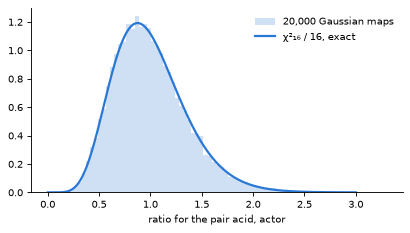

In [2]:
a = X[0] - X[1]
rng = np.random.default_rng(7)
k = 16
sims = np.array([((a @ jl.projection(len(a), k, "gaussian", rng)) ** 2).sum() for _ in range(20_000)]) / (a @ a)
grid = np.linspace(0, 3, 300)
fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(sims, bins=80, density=True, color="#cfe0f5", label="20,000 Gaussian maps")
ax.plot(grid, k * chi2.pdf(k * grid, k), color="#2a78d6", lw=2, label="χ²₁₆ / 16, exact")
ax.set_xlabel(f"ratio for the pair {words[0]}, {words[1]}")
ax.legend(frameon=False)
inside = np.mean(np.abs(sims - 1) <= 0.5)
print(f"share of ratios within 1 ± 0.5: {inside:.4f}; exact {1 - jl.gaussian_pair_tail(k, 0.5):.4f}")

The binary and sparse maps are not spherically symmetric, so their ratio depends on the pair. Its variance can still be computed exactly. With z = Σᵢ rᵢaᵢ, E z² = |a|², and E z⁴ = 3|a|⁴ + (m₄ − 3) Σᵢ aᵢ⁴, where m₄ = E r⁴ is 3 for Gaussian and sparse entries and 1 for ±1 entries. The ratio averages k independent copies of z²/|a|², so its variance is (2 + (m₄ − 3) Σ aᵢ⁴/|a|⁴)/k.

Two consequences. The sparse map has the same fourth moment as the Gaussian, so the same variance on every pair. The ±1 map has a smaller variance, by an amount that is large only when the difference vector a is concentrated on a few coordinates. The word vectors spread over 256 coordinates; the Pokémon stats have six, and Shuckle (230 Defense and Special Defense, 20 Attack) against Blissey (255 HP) is about as lopsided as a pair gets. Twenty thousand maps of each kind:

In [3]:
var = study.variance_check()
print(f"{'':8} {'kind':9} {'mean':>6} {'variance':>9} {'± se':>6} {'exact':>7}")
for name, rows in var.items():
    for kind, r in rows.items():
        print(f"{name:8} {kind:9} {r['mean']:6.3f} {r['variance']:9.4f} {r['variance_se']:6.4f} {r['exact_variance']:7.4f}")

         kind        mean  variance   ± se   exact
words    gaussian   0.999    0.1259 0.0015  0.1250
words    binary     0.998    0.1229 0.0015  0.1234
words    sparse     0.998    0.1254 0.0015  0.1250
pokemon  gaussian   1.002    0.1270 0.0015  0.1250
pokemon  binary     0.998    0.0764 0.0008  0.0768
pokemon  sparse     1.001    0.1265 0.0014  0.1250


Each simulated variance is within two standard errors of the exact one. For the lopsided pair the ±1 map's variance is 39% below the Gaussian's.

## All pairs

There are C(400, 2) = 79,800 pairs of words. For each k from 4 to 1,024 and each kind, draw 20 maps (seeds 0 to 19) and record the distortion. The two dashed lines are bounds on the distortion that hold with probability at least 1 − 1/n:

- **Achlioptas (β = 1)**: the closed form k = (4 + 2β) ln n / (ε²/2 − ε³/3), solved for ε. It holds for all three kinds. Dasgupta and Gupta's k = 4 ln n / (ε²/2 − ε³/3) is the case β = 0, which guarantees success only with probability 1/n.
- **Exact union bound**: the ε at which C(n, 2) times the exact χ² tail of one pair equals 1/n. This is the proof's own argument with the Chernoff estimate replaced by the exact tail, so for Gaussian maps no union-bound proof can do better.

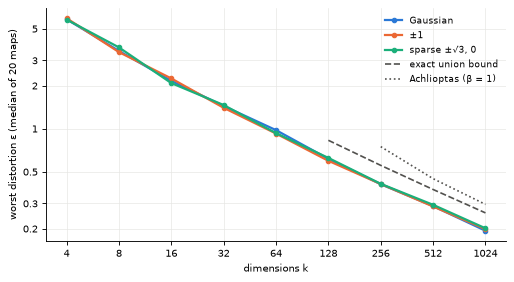

In [4]:
worst = study.jl_worst()
res = study.jl_section()
fig = figures.jl_plot()

In [5]:
r = res["words"]
print(f"{'k':>5} {'Gaussian':>9} {'±1':>6} {'sparse':>7} {'union':>7} {'Achlioptas':>10}")
for i, k in enumerate(r["k"]):
    m = [r["median_worst"][kind][i] for kind in jl.KINDS]
    u, ach = r["bounds"]["union_chi2"][i], r["bounds"]["achlioptas_beta1"][i]
    print(f"{k:5} {m[0]:9.3f} {m[1]:6.3f} {m[2]:7.3f} {u:7.3f} {ach:10.3f}")

    k  Gaussian     ±1  sparse   union Achlioptas
    4     5.823  5.917   5.791     nan        nan
    8     3.497  3.431   3.700     nan        nan
   16     2.160  2.245   2.083     nan        nan
   32     1.440  1.400   1.463     nan        nan
   64     0.977  0.924   0.931     nan        nan
  128     0.615  0.596   0.624   0.829        nan
  256     0.409  0.410   0.412   0.554      0.749
  512     0.288  0.286   0.294   0.376      0.447
 1024     0.193  0.198   0.201   0.258      0.296


Medians of 20 maps. A blank bound (nan) means the bound promises nothing below ε = 1 at that k.

- The three kinds of map are indistinguishable at every k: the sparse map, which reads a third of the coordinates, loses nothing measurable.
- The exact union bound at failure chance 1/n sits about a third above the median worst distortion (31% to 35% for k from 128 to 1,024). Part of that gap is the union bound counting overlapping bad events as if they were disjoint; part is asking for success with chance 1 − 1/n instead of the median map.
- Achlioptas's closed form is another 15% to 35% above the exact union bound: the price of the Chernoff estimate and the ε³ term.
- To keep every distance within 20% in squared length needs about 1,000 dimensions, four times the 256 the words started in. The lemma's k does not depend on d, and for 400 points it is not small: at ε = 1/2, Dasgupta and Gupta's formula asks for 288 dimensions and Achlioptas's for 432. A random projection pays off only when d is far larger than that.

## Pokémon: when d is already small

The Pokémon have six stats. The lemma's k for ε = 1/2 and 705 points is 315 dimensions, 50 times d. Random maps to fewer than six dimensions distort a lot. Principal components do much better, because they keep the directions where the stats vary. PCA never stretches a distance, so its distortion is 1 minus its smallest ratio.

In [6]:
r = res["pokemon"]
xc = stats - stats.mean(axis=0)
_, _, vt = np.linalg.svd(xc, full_matrices=False)
print(f"Dasgupta and Gupta's k for eps = 1/2 and n = 705: {r['bounds']['k_for_eps_half']:.0f}")
print(f"{'k':>3} {'Gaussian':>9} {'±1':>6} {'sparse':>7} {'PCA':>6}")
for i, k in enumerate(r["k"]):
    m = [r["median_worst"][kind][i] for kind in jl.KINDS]
    pca = jl.worst(jl.ratios(xc, vt[:k].T)) if k <= 6 else float("nan")
    print(f"{k:3} {m[0]:9.3f} {m[1]:6.3f} {m[2]:7.3f} {pca:6.3f}")

Dasgupta and Gupta's k for eps = 1/2 and n = 705: 315
  k  Gaussian     ±1  sparse    PCA
  1     5.173  4.935   4.956  1.000
  2     3.319  2.960   3.806  1.000
  3     2.979  2.459   3.392  0.999
  6     1.678  1.262   2.104  0.000
 12     1.081  0.990   1.182    nan
 24     0.850  0.758   0.783    nan
 48     0.547  0.498   0.587    nan
 96     0.424  0.335   0.435    nan


At k = 6 PCA is a rotation and keeps every distance; random maps to six dimensions still have worst distortions of 1.26 to 2.10. At small d the ±1 map does better than the Gaussian and the sparse map worse, as the variance formula and the zeros suggest: a sparse column of six entries is entirely zero with chance (2/3)⁶ ≈ 9%.

## The proof in plain words

Dasgupta and Gupta's proof (2003) has two steps.

1. **Concentration for one pair.** The ratio is an average of k independent squares, so it is rarely far from its mean. Markov's inequality applied to e^{t·(sum)} with the best t (a Chernoff bound) gives, for one pair, a chance at most exp(−k(ε²/2 − ε³/3)/2) of a ratio above 1 + ε, and at most exp(−kε²/4) of a ratio below 1 − ε. Both are at most 1/n² when k ≥ 4 ln n / (ε²/2 − ε³/3).
2. **Union bound over pairs.** There are n(n − 1)/2 pairs, each fails with chance at most 2/n², so some pair fails with chance at most 1 − 1/n. One map works with chance at least 1/n, and repeating the draw makes failure as rare as one likes. Achlioptas proves the same per-pair estimate for ±1 and sparse entries by showing their even moments are at most the Gaussian's, which spends an extra β ln n in k to make a single draw succeed with chance 1 − n^{−β}.

The check below confirms step 1 numerically: at Dasgupta and Gupta's ε, the exact chance that one pair fails is below 2/n².

In [7]:
n = 400
for k in (300, 600, 1000):
    eps = jl.eps_bound(n, k)
    print(f"k = {k:4}: eps {eps:.3f}, exact pair failure {jl.gaussian_pair_tail(k, eps):.2e} <= 2/n^2 = {2 / n**2:.2e}")

k =  300: eps 0.486, exact pair failure 8.86e-08 <= 2/n^2 = 1.25e-05
k =  600: eps 0.318, exact pair failure 2.35e-07 <= 2/n^2 = 1.25e-05
k = 1000: eps 0.239, exact pair failure 3.22e-07 <= 2/n^2 = 1.25e-05


## Variations and open questions

- **Fast transforms.** Ailon and Chazelle's fast Johnson-Lindenstrauss transform multiplies by a random sign diagonal and a Hadamard matrix before a sparse projection; it should behave like the maps here.
- **Lower bounds.** Larsen and Nelson (2017) showed that O(log n / ε²) dimensions are needed in the worst case for any linear or nonlinear map. These word vectors are not the worst case: how much lower can a data-aware map (PCA, or a learned one) go while keeping every distance within 20%?
- **Inner products.** Codenames guessers rank words by cosine similarity, not distance. How often a random map changes a guesser's choice is a sharper question than distortion.

## The numbers the README quotes

In [8]:
assert study.same(study.rounded(res), study.stored()["jl"])
print("jl section matches maps/results/maps.json")

jl section matches maps/results/maps.json
